# Setup

In [ ]:
import time, copy, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import pandas as pd

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(42)

CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
BATCH_SIZE = 128
VAL_SIZE = 5000
NUM_WORKERS = 2

Device: cuda


In [ ]:
CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

# Fixed split of the 50k training images into 45k train / 5k validation
g = torch.Generator().manual_seed(42)
perm = torch.randperm(50000, generator=g).tolist()
val_idx, train_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]

def get_loaders(mean, std):
    train_tf = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    eval_tf = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    # Load the training set twice so validation gets NO augmentation
    train_full = datasets.CIFAR10("./data", train=True, download=True, transform=train_tf)
    val_full   = datasets.CIFAR10("./data", train=True, download=True, transform=eval_tf)
    test_set   = datasets.CIFAR10("./data", train=False, download=True, transform=eval_tf)

    train_loader = DataLoader(Subset(train_full, train_idx), batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=True)
    val_loader   = DataLoader(Subset(val_full, val_idx), batch_size=256, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)
    test_loader  = DataLoader(test_set, batch_size=256, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = get_loaders(CIFAR_MEAN, CIFAR_STD)
print(f"Train: {len(train_loader.dataset)} | Val: {len(val_loader.dataset)} | Test: {len(test_loader.dataset)}")

100%|██████████| 170M/170M [07:48<00:00, 364kB/s]


Train: 45000 | Val: 5000 | Test: 10000


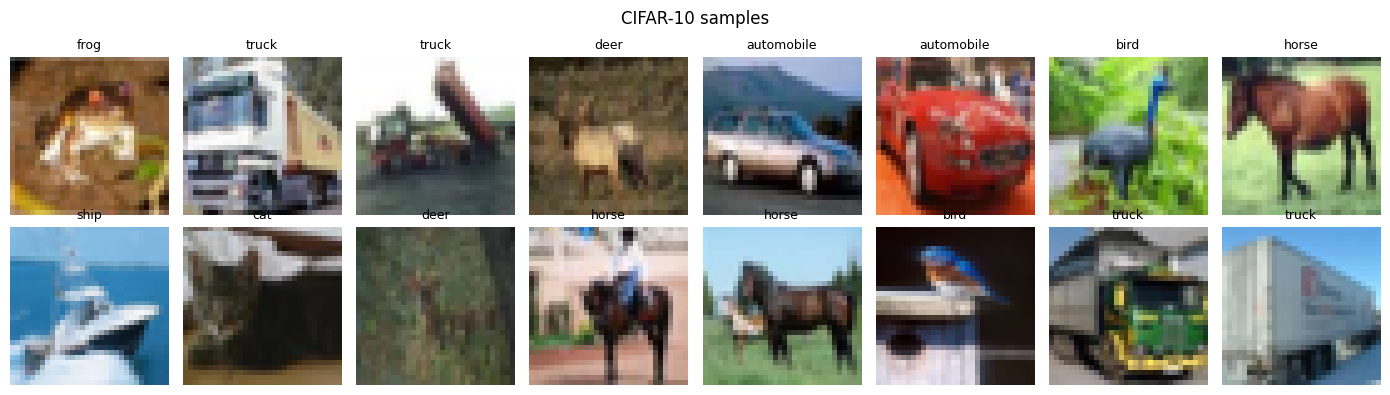

In [ ]:
raw = datasets.CIFAR10("./data", train=True, download=True)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.flat, range(16)):
    img, label = raw[i]
    ax.imshow(img); ax.set_title(CLASSES[label], fontsize=9); ax.axis("off")
plt.suptitle("CIFAR-10 samples"); plt.tight_layout(); plt.show()

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, scheduler=None, frozen_backbone=None):
    model.train()
    if frozen_backbone is not None:
        frozen_backbone.eval()   # keep BatchNorm stats fixed when the backbone is frozen
    scaler = train_one_epoch.scaler
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
            out = model(x)
            loss = criterion(out, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        if scheduler is not None:
            scheduler.step()     # per-batch scheduler
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n

train_one_epoch.scaler = torch.amp.GradScaler(enabled=(device == "cuda"))

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
            out = model(x)
            loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n

def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))

# Part 1: Training with a CNN from scratch

In [ ]:
def conv_block(in_c, out_c, drop):
    return nn.Sequential(
        nn.Conv2d(in_c, out_c, 3, padding=1, bias=False), nn.BatchNorm2d(out_c), nn.ReLU(inplace=True),
        nn.Conv2d(out_c, out_c, 3, padding=1, bias=False), nn.BatchNorm2d(out_c), nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
        nn.Dropout(drop),
    )

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 64, 0.1),     # 32 -> 16
            conv_block(64, 128, 0.2),   # 16 -> 8
            conv_block(128, 256, 0.3),  # 8  -> 4
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(256, 256), nn.ReLU(inplace=True), nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

cnn = SimpleCNN().to(device)
print(cnn)
print(f"Parameters: {count_params(cnn):,}")

SimpleCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.1, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1

In [ ]:
CNN_EPOCHS = 30
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(cnn.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4, nesterov=True)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.1, epochs=CNN_EPOCHS,
                                                steps_per_epoch=len(train_loader))

cnn_hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc, best_state = 0.0, None
start = time.time()

for epoch in range(1, CNN_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(cnn, train_loader, optimizer, criterion, scheduler)
    va_loss, va_acc = evaluate(cnn, val_loader, criterion)
    for k, v in zip(cnn_hist, [tr_loss, tr_acc, va_loss, va_acc]):
        cnn_hist[k].append(v)
    if va_acc > best_val_acc:
        best_val_acc, best_state = va_acc, copy.deepcopy(cnn.state_dict())
    print(f"Epoch {epoch:02d}/{CNN_EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
          f"| val loss {va_loss:.4f} acc {va_acc:.4f}")

cnn_train_time = time.time() - start
print(f"\nTraining time: {cnn_train_time/60:.1f} min | Best val acc: {best_val_acc:.4f}")

Epoch 01/30 | train loss 1.5825 acc 0.4032 | val loss 1.2765 acc 0.5482
Epoch 02/30 | train loss 1.1303 acc 0.5912 | val loss 1.0548 acc 0.6264
Epoch 03/30 | train loss 0.9646 acc 0.6594 | val loss 0.9053 acc 0.6842
Epoch 04/30 | train loss 0.8529 acc 0.7018 | val loss 1.2112 acc 0.6432
Epoch 05/30 | train loss 0.7749 acc 0.7332 | val loss 0.8985 acc 0.6994
Epoch 06/30 | train loss 0.6982 acc 0.7604 | val loss 0.7727 acc 0.7402
Epoch 07/30 | train loss 0.6427 acc 0.7788 | val loss 0.8403 acc 0.7232
Epoch 08/30 | train loss 0.6019 acc 0.7958 | val loss 0.6026 acc 0.7912
Epoch 09/30 | train loss 0.5725 acc 0.8052 | val loss 0.5499 acc 0.8156
Epoch 10/30 | train loss 0.5387 acc 0.8174 | val loss 0.6027 acc 0.8010
Epoch 11/30 | train loss 0.5240 acc 0.8218 | val loss 0.6435 acc 0.7854
Epoch 12/30 | train loss 0.5033 acc 0.8289 | val loss 0.6504 acc 0.7882
Epoch 13/30 | train loss 0.4909 acc 0.8330 | val loss 0.6651 acc 0.7792
Epoch 14/30 | train loss 0.4741 acc 0.8395 | val loss 0.6061 acc

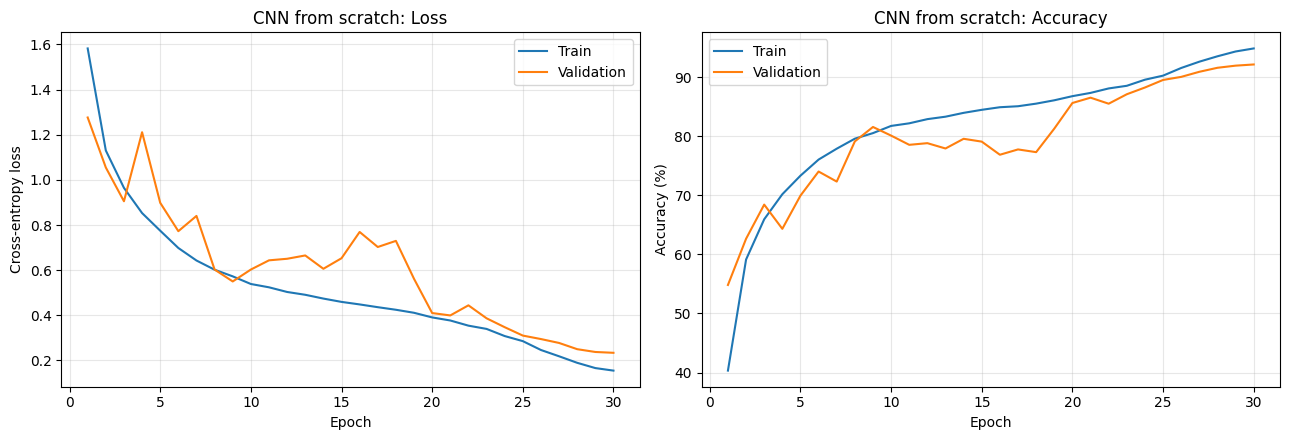

In [ ]:
epochs = range(1, len(cnn_hist["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(epochs, cnn_hist["train_loss"], label="Train")
ax1.plot(epochs, cnn_hist["val_loss"], label="Validation")
ax1.set_title("CNN from scratch: Loss"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Cross-entropy loss")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, [a*100 for a in cnn_hist["train_acc"]], label="Train")
ax2.plot(epochs, [a*100 for a in cnn_hist["val_acc"]], label="Validation")
ax2.set_title("CNN from scratch: Accuracy"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy (%)")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("cnn_curves.png", dpi=150)
plt.show()

In [ ]:
cnn.load_state_dict(best_state)
cnn_test_loss, cnn_test_acc = evaluate(cnn, test_loader, criterion)
print(f"CNN test accuracy: {cnn_test_acc*100:.2f}%  (test loss {cnn_test_loss:.4f})")

@torch.no_grad()
def per_class_accuracy(model, loader):
    model.eval()
    correct, total = torch.zeros(10), torch.zeros(10)
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        preds = model(x).argmax(1)
        for c in range(10):
            mask = y == c
            correct[c] += (preds[mask] == c).sum().item()
            total[c] += mask.sum().item()
    return (correct / total * 100).numpy()

print(pd.DataFrame({"Class": CLASSES, "CNN acc (%)": per_class_accuracy(cnn, test_loader).round(1)}))

CNN test accuracy: 91.56%  (test loss 0.2597)
        Class  CNN acc (%)
0    airplane    92.900002
1  automobile    95.800003
2        bird    87.199997
3         cat    80.599998
4        deer    93.599998
5         dog    86.599998
6        frog    95.199997
7       horse    93.099998
8        ship    95.400002
9       truck    95.300003


# Part 2: Transfer Learning with ResNet-18

In [ ]:
tl_train_loader, tl_val_loader, tl_test_loader = get_loaders(IMAGENET_MEAN, IMAGENET_STD)

IMG_SIZE = 224

class UpsampledResNet(nn.Module):
    def __init__(self, num_classes=10, size=IMG_SIZE):
        super().__init__()
        self.size = size
        self.backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, num_classes)  # 512 -> 10
    def forward(self, x):
        x = F.interpolate(x, size=self.size, mode="bilinear", align_corners=False)
        return self.backbone(x)

resnet = UpsampledResNet().to(device)
print(f"ResNet-18 parameters: {count_params(resnet):,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s]


ResNet-18 parameters: 11,181,642


In [ ]:
HEAD_EPOCHS = 2
for name, p in resnet.backbone.named_parameters():
    p.requires_grad = name.startswith("fc.")
print(f"Trainable params (stage 1): {count_params(resnet, trainable_only=True):,}")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(resnet.backbone.fc.parameters(), lr=1e-3)
resnet_hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

start = time.time()
for epoch in range(1, HEAD_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(resnet, tl_train_loader, optimizer, criterion,
                                      frozen_backbone=resnet.backbone)
    resnet.backbone.fc.train()
    va_loss, va_acc = evaluate(resnet, tl_val_loader, criterion)
    for k, v in zip(resnet_hist, [tr_loss, tr_acc, va_loss, va_acc]):
        resnet_hist[k].append(v)
    print(f"[Head] Epoch {epoch}/{HEAD_EPOCHS} | train acc {tr_acc:.4f} | val acc {va_acc:.4f}")
stage1_time = time.time() - start

_, fe_test_acc = evaluate(resnet, tl_test_loader, criterion)
print(f"\nFeature-extraction test accuracy: {fe_test_acc*100:.2f}%")

Trainable params (stage 1): 5,130
[Head] Epoch 1/2 | train acc 0.7756 | val acc 0.8510
[Head] Epoch 2/2 | train acc 0.8468 | val acc 0.8666

Feature-extraction test accuracy: 85.25%


In [ ]:
FT_EPOCHS = 3
for p in resnet.parameters():
    p.requires_grad = True

optimizer = torch.optim.AdamW(resnet.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FT_EPOCHS * len(tl_train_loader))

best_val_acc_tl, best_state_tl = 0.0, None
start = time.time()
for epoch in range(1, FT_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(resnet, tl_train_loader, optimizer, criterion, scheduler)
    va_loss, va_acc = evaluate(resnet, tl_val_loader, criterion)
    for k, v in zip(resnet_hist, [tr_loss, tr_acc, va_loss, va_acc]):
        resnet_hist[k].append(v)
    if va_acc > best_val_acc_tl:
        best_val_acc_tl, best_state_tl = va_acc, copy.deepcopy(resnet.state_dict())
    print(f"[Fine-tune] Epoch {epoch}/{FT_EPOCHS} | train acc {tr_acc:.4f} | val acc {va_acc:.4f}")
stage2_time = time.time() - start
resnet_train_time = stage1_time + stage2_time
print(f"\nTotal ResNet training time: {resnet_train_time/60:.1f} min")

[Fine-tune] Epoch 1/3 | train acc 0.9005 | val acc 0.9368
[Fine-tune] Epoch 2/3 | train acc 0.9553 | val acc 0.9538
[Fine-tune] Epoch 3/3 | train acc 0.9754 | val acc 0.9578

Total ResNet training time: 4.4 min


In [ ]:
resnet.load_state_dict(best_state_tl)
resnet_test_loss, resnet_test_acc = evaluate(resnet, tl_test_loader, criterion)
print(f"ResNet-18 (fine-tuned) test accuracy: {resnet_test_acc*100:.2f}%")

ResNet-18 (fine-tuned) test accuracy: 94.83%


# Part 3: Performance Comparison & Analysis

,Model,Test accuracy (%),Parameters,Epochs,Training time (min),Input size
0,CNN from scratch,91.56,1214666,30,8.34,32x32
1,ResNet-18 (feature extraction),85.25,11181642,2,0.84,224x224
2,ResNet-18 (fine-tuned),94.83,11181642,5,4.42,224x224


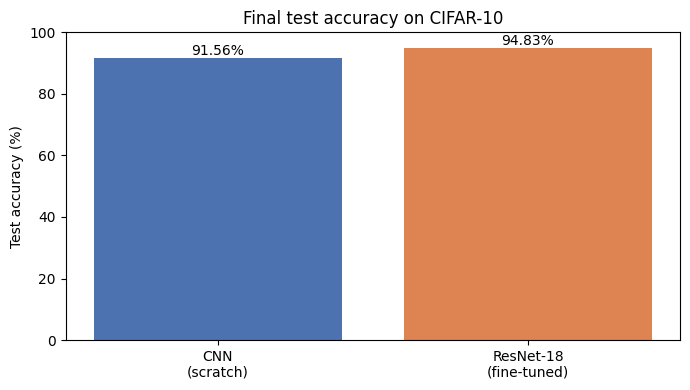

In [ ]:
results = pd.DataFrame({
    "Model": ["CNN from scratch", "ResNet-18 (feature extraction)", "ResNet-18 (fine-tuned)"],
    "Test accuracy (%)": [cnn_test_acc*100, fe_test_acc*100, resnet_test_acc*100],
    "Parameters": [count_params(cnn), count_params(resnet), count_params(resnet)],
    "Epochs": [CNN_EPOCHS, HEAD_EPOCHS, HEAD_EPOCHS + FT_EPOCHS],
    "Training time (min)": [cnn_train_time/60, stage1_time/60, resnet_train_time/60],
    "Input size": ["32x32", f"{IMG_SIZE}x{IMG_SIZE}", f"{IMG_SIZE}x{IMG_SIZE}"],
}).round(2)
display(results)

plt.figure(figsize=(7, 4))
bars = plt.bar(["CNN\n(scratch)", "ResNet-18\n(fine-tuned)"],
               [cnn_test_acc*100, resnet_test_acc*100], color=["#4C72B0", "#DD8452"])
plt.bar_label(bars, fmt="%.2f%%")
plt.ylabel("Test accuracy (%)"); plt.ylim(0, 100)
plt.title("Final test accuracy on CIFAR-10")
plt.tight_layout(); plt.savefig("accuracy_comparison.png", dpi=150); plt.show()